<a href="https://colab.research.google.com/github/rahafabumwise/CV_Assistant/blob/main/CV_Assistant_Phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/rahafabumwise/CV_Assistant.git /content/CV_Assistant

Cloning into '/content/CV_Assistant'...
remote: Enumerating objects: 96, done.
remote: Counting objects: 100% (96/96), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 96 (delta 32), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (96/96), 59.58 KiB | 3.97 MiB/s, done.
Resolving deltas: 100% (32/32), done.


In [2]:
%cd /content/CV_Assistant

/content/CV_Assistant


In [3]:
from pathlib import Path
import csv

# Find the documents used for continued pretraining.
documents = sorted(Path("data/cpt/documents").glob("*.txt"))

total_words = 0

for document in documents:
    text = document.read_text(encoding="utf-8")
    word_count = len(text.split())
    total_words += word_count

    print(f"{document.name}: {word_count} words")

# Read the separate evaluation questions.
with open("tests/test_questions.csv", encoding="utf-8", newline="") as file:
    test_questions = list(csv.DictReader(file))

print("\nNumber of documents:", len(documents))
print("Total words:", total_words)
print("Number of test questions:", len(test_questions))

oregon_cv_preparation.txt: 682 words
oregon_resume_formats.txt: 437 words
oregon_resume_sections_and_guidelines.txt: 1603 words
tru_action_verbs.txt: 176 words
tru_education_training_and_certificates.txt: 370 words
tru_employment_or_work_experience.txt: 350 words
tru_hobbies_interest.txt: 114 words
tru_modern_resume_formatting.txt: 1022 words
tru_overall_format.txt: 449 words
tru_transferable_skills.txt: 355 words
tru_volunteering_community_involvement.txt: 183 words

Number of documents: 11
Total words: 5741
Number of test questions: 30


In [4]:
%pip install -q transformers

In [5]:
from transformers import AutoTokenizer
import transformers

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")

sentence = "I am writing my first CV."

token_ids = tokenizer.encode(sentence, add_special_tokens=False)

print("Text:", sentence)
print("Token pieces:", [tokenizer.decode([i]) for i in token_ids])
print("Token IDs:", token_ids)
print("Number of tokens:", len(token_ids))
print("Transformers version:", transformers.__version__)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Text: I am writing my first CV.
Token pieces: ['I', ' am', ' writing', ' my', ' first', ' CV', '.']
Token IDs: [40, 716, 3597, 616, 717, 26196, 13]
Number of tokens: 7
Transformers version: 5.22.1


In [7]:
from pathlib import Path

documents = sorted(
    Path("/content/CV_Assistant/data/cpt/documents").glob("*.txt")
)

assert len(documents) == 11, "Expected 11 text files. Check the folder."

document_token_counts = {}
total_tokens = 0

for document in documents:
    text = document.read_text(encoding="utf-8")

    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False,
        verbose=False
    )

    document_token_counts[document.name] = len(token_ids)
    total_tokens += len(token_ids)

    print(f"{document.name}: {len(token_ids):,} tokens")

print(f"\nTotal document tokens: {total_tokens:,}")

oregon_cv_preparation.txt: 890 tokens
oregon_resume_formats.txt: 661 tokens
oregon_resume_sections_and_guidelines.txt: 2,381 tokens
tru_action_verbs.txt: 339 tokens
tru_education_training_and_certificates.txt: 445 tokens
tru_employment_or_work_experience.txt: 420 tokens
tru_hobbies_interest.txt: 145 tokens
tru_modern_resume_formatting.txt: 1,362 tokens
tru_overall_format.txt: 554 tokens
tru_transferable_skills.txt: 497 tokens
tru_volunteering_community_involvement.txt: 233 tokens

Total document tokens: 7,927


In [9]:
from pathlib import Path
import json

project_folder = Path("/content/CV_Assistant")
documents_folder = project_folder / "data/cpt/documents"

documents = sorted(documents_folder.glob("*.txt"))
assert len(documents) == 11, "Expected 11 documents."

# Keep one complete document aside for validation.
validation_name = "oregon_cv_preparation.txt"

validation_files = [p for p in documents if p.name == validation_name]
training_files = [p for p in documents if p.name != validation_name]

assert len(training_files) == 10
assert len(validation_files) == 1

def count_tokens(files):
    return sum(
        len(tokenizer.encode(
            p.read_text(encoding="utf-8"),
            add_special_tokens=False,
            truncation=False,
            verbose=False
        ))
        for p in files
    )

split = {
    "train": [
        p.relative_to(project_folder).as_posix()
        for p in training_files
    ],
    "validation": [
        p.relative_to(project_folder).as_posix()
        for p in validation_files
    ]
}

split_path = project_folder / "data/cpt/split.json"
split_path.write_text(json.dumps(split, indent=2), encoding="utf-8")

print("Training documents:", len(training_files))
print("Training tokens:", count_tokens(training_files))
print("Validation documents:", len(validation_files))
print("Validation tokens:", count_tokens(validation_files))
print("Split saved to:", split_path)

Training documents: 10
Training tokens: 7037
Validation documents: 1
Validation tokens: 890
Split saved to: /content/CV_Assistant/data/cpt/split.json


In [10]:
import json
import re
from pathlib import Path

project_folder = Path("/content/CV_Assistant")

split = json.loads(
    (project_folder / "data/cpt/split.json").read_text(encoding="utf-8")
)

def word_sequences(file_path, length=15):
    text = file_path.read_text(encoding="utf-8").lower()
    words = re.findall(r"\b\w+\b", text)

    return {
        tuple(words[i:i + length])
        for i in range(len(words) - length + 1)
    }

matches_found = False

for validation_path in split["validation"]:
    validation_sequences = word_sequences(project_folder / validation_path)

    for training_path in split["train"]:
        training_sequences = word_sequences(project_folder / training_path)
        shared = validation_sequences & training_sequences

        if shared:
            matches_found = True
            print(f"\nTraining: {Path(training_path).name}")
            print(f"Validation: {Path(validation_path).name}")
            print(f"Matching 15-word sequences: {len(shared)}")

            for example in sorted(shared)[:2]:
                print("Example:", " ".join(example))

if not matches_found:
    print("No exact 15-word matches found between training and validation.")

No exact 15-word matches found between training and validation.


In [11]:
from google.colab import files

files.download("/content/CV_Assistant/data/cpt/split.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

GPU

In [1]:
import torch
from pathlib import Path

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

print(
    "Project files still available:",
    Path("/content/CV_Assistant/data/cpt/split.json").exists()
)

GPU available: True
GPU name: Tesla T4
Project files still available: False


In [2]:
# Restore the project from GitHub.
!git clone https://github.com/rahafabumwise/CV_Assistant.git /content/CV_Assistant

Cloning into '/content/CV_Assistant'...
remote: Enumerating objects: 101, done.
remote: Counting objects: 100% (101/101), done.
remote: Compressing objects: 100% (85/85), done.
remote: Total 101 (delta 34), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (101/101), 60.68 KiB | 3.79 MiB/s, done.
Resolving deltas: 100% (34/34), done.


In [3]:
from pathlib import Path
import json

project_folder = Path("/content/CV_Assistant")
documents = sorted(
    (project_folder / "data/cpt/documents").glob("*.txt")
)
split_path = project_folder / "data/cpt/split.json"

print("Documents found:", len(documents))
print("Split file found:", split_path.exists())

if split_path.exists():
    split = json.loads(split_path.read_text(encoding="utf-8"))
    print("Training documents:", len(split["train"]))
    print("Validation documents:", len(split["validation"]))
else:
    print("The split file needs to be restored.")

Documents found: 11
Split file found: True
Training documents: 10
Validation documents: 1


In [4]:
%pip install -q "transformers==4.57.1" "accelerate==1.11.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [5]:
import sys
import torch
import transformers
import accelerate

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("GPU available:", torch.cuda.is_available())

Python: 3.13.16
PyTorch: 2.14.1+cu130
Transformers: 4.57.1
Accelerate: 1.11.0
GPU available: True


In [6]:
%pip uninstall -y gradio gradio-client diffusers

Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [7]:
%pip check

ipython 7.34.0 requires jedi, which is not installed.
hf-gradio 0.4.1 requires gradio-client, which is not installed.


In [8]:
%pip install -q "jedi==0.19.2"
%pip uninstall -y hf-gradio
%pip check

Found existing installation: hf-gradio 0.4.1
Uninstalling hf-gradio-0.4.1:
  Successfully uninstalled hf-gradio-0.4.1
No broken requirements found.


In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

# Make random operations more reproducible.
set_seed(42)

assert torch.cuda.is_available(), "Please reconnect to a GPU runtime."

model_name = "openai-community/gpt2"

# Load the tokenizer: converts text into token IDs.
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Use the existing end-of-text token for padding.
tokenizer.pad_token = tokenizer.eos_token

# Load the original model and move it to the GPU.
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    use_safetensors=True
).to("cuda")

model.config.pad_token_id = tokenizer.pad_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id

# Evaluation mode: we are not training yet.
model.eval()

parameter_count = sum(p.numel() for p in model.parameters())

print("Model:", model_name)
print(f"Parameters: {parameter_count:,}")
print("Device:", next(model.parameters()).device)
print("Model loaded successfully.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: openai-community/gpt2
Parameters: 124,439,808
Device: cuda:0
Model loaded successfully.


In [10]:
import json
import math
from pathlib import Path
import torch

project_folder = Path("/content/CV_Assistant")
split = json.loads(
    (project_folder / "data/cpt/split.json").read_text(encoding="utf-8")
)

# We will reuse this exact evaluation method after training.
def evaluate_validation(model, tokenizer):
    model.eval()
    device = next(model.parameters()).device

    total_loss = 0.0
    total_scored_tokens = 0

    for filename in split["validation"]:
        text = (project_folder / filename).read_text(encoding="utf-8")
        token_ids = tokenizer.encode(text, add_special_tokens=False)
        previous_end = 0

        # Overlapping windows preserve some context between chunks.
        for start in range(0, len(token_ids), 256):
            end = min(start + 512, len(token_ids))
            new_tokens = end - previous_end

            inputs = torch.tensor(
                [token_ids[start:end]], device=device
            )
            labels = inputs.clone()

            # Ignore overlapping tokens already evaluated.
            labels[:, :-new_tokens] = -100

            # GPT-2 predicts each token from preceding tokens.
            scored_tokens = (labels[:, 1:] != -100).sum().item()

            if scored_tokens > 0:
                with torch.no_grad():
                    output = model(
                        input_ids=inputs,
                        labels=labels,
                        use_cache=False
                    )

                total_loss += output.loss.item() * scored_tokens
                total_scored_tokens += scored_tokens

            previous_end = end
            if end == len(token_ids):
                break

    assert total_scored_tokens > 0, "No validation tokens to evaluate."
    mean_loss = total_loss / total_scored_tokens

    return {
        "validation_loss": mean_loss,
        "perplexity": math.exp(mean_loss),
        "scored_tokens": total_scored_tokens,
        "context_length": 512,
        "stride": 256
    }

baseline = evaluate_validation(model, tokenizer)

results_folder = project_folder / "results"
results_folder.mkdir(exist_ok=True)

result_path = results_folder / "base_validation_metrics.json"
result_path.write_text(
    json.dumps(baseline, indent=2), encoding="utf-8"
)

print(f"Baseline validation loss: {baseline['validation_loss']:.4f}")
print(f"Baseline perplexity: {baseline['perplexity']:.2f}")
print("Scored tokens:", baseline["scored_tokens"])
print("Results saved to:", result_path)

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Baseline validation loss: 2.9879
Baseline perplexity: 19.84
Scored tokens: 889
Results saved to: /content/CV_Assistant/results/base_validation_metrics.json


In [11]:
import json
import torch

completion_prompts = [
    "When writing your first CV,",
    "An effective education section",
    "To describe your work experience,",
    "When including volunteer experience on a CV,",
    "A clearly formatted CV"
]

generation_settings = {
    "max_new_tokens": 80,
    "do_sample": False,
    "num_beams": 1
}

model.eval()
base_completions = []

for number, prompt in enumerate(completion_prompts, start=1):
    inputs = tokenizer(prompt, return_tensors="pt").to(
        next(model.parameters()).device
    )

    with torch.no_grad():
        output = model.generate(
            **inputs,
            **generation_settings,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Save only the newly generated text as the completion.
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    completion = tokenizer.decode(new_tokens, skip_special_tokens=True)

    base_completions.append({
        "id": number,
        "prompt": prompt,
        "completion": completion
    })

    print(f"\nPrompt {number}: {prompt}")
    print("Completion:", completion)

output_path = results_folder / "base_completions.json"
output_path.write_text(
    json.dumps({
        "model": model_name,
        "generation_settings": generation_settings,
        "examples": base_completions
    }, indent=2),
    encoding="utf-8"
)

print("\nSaved to:", output_path)


Prompt 1: When writing your first CV,
Completion:  you should always be aware of the following:

What you are writing is not your own.

You are not writing for yourself.

You are not writing for your company.

You are not writing for yourself.

You are not writing for yourself.

You are not writing for yourself.

You are not writing for yourself.

You are not

Prompt 2: An effective education section
Completion:  of the bill would require that the state provide a minimum of $1,000 per student for each student enrolled in a public school.

The bill would also require that the state provide a minimum of $1,000 per student for each student enrolled in a private school.

The bill would also require that the state provide a minimum of $1,000 per student for each student enrolled

Prompt 3: To describe your work experience,
Completion:  please see the following:

How do I get started?

You can start by downloading the latest version of the app from the App Store.

How do I get started with 

In [12]:
import torch
from torch.utils.data import Dataset

# Combine ONLY the training documents.
training_token_ids = []

for filename in split["train"]:
    text = (project_folder / filename).read_text(encoding="utf-8")

    document_tokens = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False,
        verbose=False
    )

    training_token_ids.extend(document_tokens)
    training_token_ids.append(tokenizer.eos_token_id)

class CVTrainingDataset(Dataset):
    def __init__(self, token_ids, block_size=512):
        self.examples = []

        for start in range(0, len(token_ids), block_size):
            chunk = token_ids[start:start + block_size]
            real_length = len(chunk)
            padding_length = block_size - real_length

            input_ids = chunk + [tokenizer.pad_token_id] * padding_length
            attention_mask = [1] * real_length + [0] * padding_length

            # -100 tells the loss function to ignore padding.
            # Real end-of-text tokens remain valid training targets.
            labels = chunk + [-100] * padding_length

            self.examples.append({
                "input_ids": torch.tensor(input_ids, dtype=torch.long),
                "attention_mask": torch.tensor(
                    attention_mask, dtype=torch.long
                ),
                "labels": torch.tensor(labels, dtype=torch.long)
            })

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]

train_dataset = CVTrainingDataset(training_token_ids)

print("Training tokens including document separators:",
      len(training_token_ids))
print("Training blocks:", len(train_dataset))
print("Tokens per block:", train_dataset[0]["input_ids"].shape[0])
print("Padding tokens in final block:",
      (train_dataset[-1]["labels"] == -100).sum().item())

Training tokens including document separators: 7047
Training blocks: 14
Tokens per block: 512
Padding tokens in final block: 121


#exp

In [13]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [14]:
from pathlib import Path
from datetime import datetime, timezone
import shutil
import subprocess
import sys

run_name = datetime.now(timezone.utc).strftime("cpt_%Y%m%d_%H%M%S")

run_folder = (
    Path("/content/drive/MyDrive/CV_Assistant/experiments") / run_name
)
run_folder.mkdir(parents=True, exist_ok=True)

# Save the baseline metrics and five original completions.
shutil.copytree(
    project_folder / "results",
    run_folder / "results",
    dirs_exist_ok=True
)

# Save the exact documents and split used in this experiment.
shutil.copytree(
    project_folder / "data/cpt",
    run_folder / "data/cpt",
    dirs_exist_ok=True
)

# Record installed package versions.
packages = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True
)
(run_folder / "environment.txt").write_text(packages, encoding="utf-8")

print("Experiment folder:", run_folder)
print("Baseline results, dataset, split, and package versions backed up.")

Experiment folder: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_024252
Baseline results, dataset, split, and package versions backed up.


In [15]:
import json
import torch
from torch.utils.data import DataLoader
from transformers import set_seed
from tqdm.auto import tqdm

# Prevent accidentally training twice in the same experiment folder.
started_file = run_folder / "training_started.txt"
with started_file.open("x", encoding="utf-8") as f:
    f.write("CPT started. Do not rerun without restoring the base model.")

set_seed(42)

training_config = {
    "model": model_name,
    "seed": 42,
    "max_epochs": 3,
    "batch_size": 2,
    "learning_rate": 5e-5,
    "weight_decay": 0.01,
    "max_grad_norm": 1.0,
    "precision": "float32",
    "block_size": 512,
    "validation_context_length": 512,
    "validation_stride": 256,
    "early_stopping": "Stop if validation loss rises versus previous epoch"
}

(run_folder / "training_config.json").write_text(
    json.dumps(training_config, indent=2), encoding="utf-8"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"]
)

device = next(model.parameters()).device
history = []
previous_validation_loss = baseline["validation_loss"]
best_cpt_loss = float("inf")
best_checkpoint = None

for epoch in range(1, training_config["max_epochs"] + 1):
    model.train()
    total_training_loss = 0.0
    total_training_tokens = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch}"):
        batch = {name: value.to(device) for name, value in batch.items()}

        optimizer.zero_grad(set_to_none=True)
        output = model(**batch, use_cache=False)
        loss = output.loss

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss. Stop and inspect.")

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), training_config["max_grad_norm"]
        )
        optimizer.step()

        scored_tokens = (batch["labels"][:, 1:] != -100).sum().item()
        total_training_loss += loss.item() * scored_tokens
        total_training_tokens += scored_tokens

    training_loss = total_training_loss / total_training_tokens

    # Reuse exactly the same evaluation function as the baseline.
    validation = evaluate_validation(model, tokenizer)

    checkpoint_folder = run_folder / "checkpoints" / f"epoch_{epoch}"
    model.save_pretrained(checkpoint_folder, safe_serialization=True)
    tokenizer.save_pretrained(checkpoint_folder)

    epoch_result = {
        "epoch": epoch,
        "training_loss": training_loss,
        **validation,
        "checkpoint": str(checkpoint_folder)
    }
    history.append(epoch_result)

    # Save results both locally and in Google Drive.
    for folder in [results_folder, run_folder / "results"]:
        (folder / "cpt_history.json").write_text(
            json.dumps(history, indent=2), encoding="utf-8"
        )

    if validation["validation_loss"] < best_cpt_loss:
        best_cpt_loss = validation["validation_loss"]
        best_checkpoint = checkpoint_folder

    print(f"\nEpoch {epoch}")
    print(f"Training loss: {training_loss:.4f}")
    print(f"Validation loss: {validation['validation_loss']:.4f}")
    print(f"Validation perplexity: {validation['perplexity']:.2f}")
    print("Checkpoint saved:", checkpoint_folder)

    if validation["validation_loss"] > previous_validation_loss:
        print("Stopping early: validation loss increased.")
        break

    previous_validation_loss = validation["validation_loss"]

selection = {
    "best_cpt_checkpoint": str(best_checkpoint),
    "best_cpt_validation_loss": best_cpt_loss,
    "baseline_validation_loss": baseline["validation_loss"],
    "improved_over_base": best_cpt_loss < baseline["validation_loss"]
}
(run_folder / "results" / "cpt_selection.json").write_text(
    json.dumps(selection, indent=2), encoding="utf-8"
)

print("\nTraining finished.")
print("Best CPT checkpoint:", best_checkpoint)
print("Improved over baseline:", selection["improved_over_base"])

Epoch 1:   0%|          | 0/7 [00:00<?, ?it/s]


Epoch 1
Training loss: 3.5742
Validation loss: 2.9540
Validation perplexity: 19.18
Checkpoint saved: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_024252/checkpoints/epoch_1


Epoch 2:   0%|          | 0/7 [00:00<?, ?it/s]


Epoch 2
Training loss: 3.2108
Validation loss: 2.9397
Validation perplexity: 18.91
Checkpoint saved: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_024252/checkpoints/epoch_2


Epoch 3:   0%|          | 0/7 [00:00<?, ?it/s]


Epoch 3
Training loss: 2.9468
Validation loss: 2.9534
Validation perplexity: 19.17
Checkpoint saved: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_024252/checkpoints/epoch_3
Stopping early: validation loss increased.

Training finished.
Best CPT checkpoint: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_024252/checkpoints/epoch_2
Improved over baseline: True


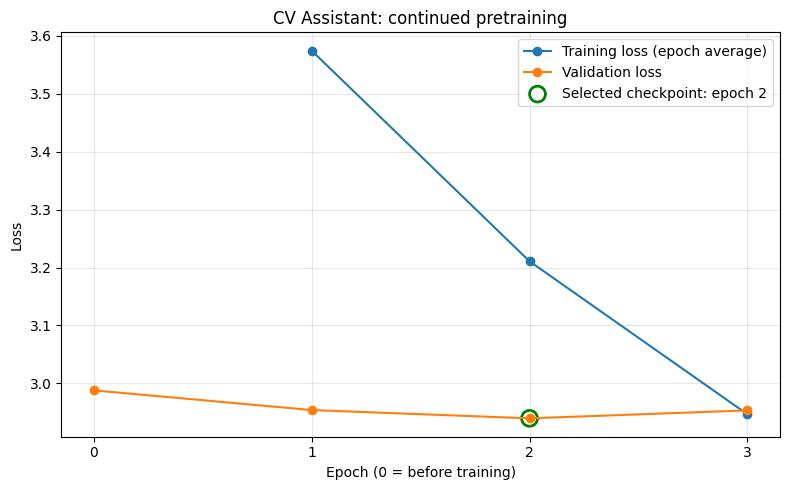

Loss graph saved locally and in Google Drive.


In [16]:
import matplotlib.pyplot as plt

epochs = [row["epoch"] for row in history]
training_losses = [row["training_loss"] for row in history]
validation_losses = [row["validation_loss"] for row in history]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs, training_losses,
    marker="o", label="Training loss (epoch average)"
)
ax.plot(
    [0] + epochs,
    [baseline["validation_loss"]] + validation_losses,
    marker="o", label="Validation loss"
)

ax.scatter(
    2, history[1]["validation_loss"],
    s=130, facecolors="none", edgecolors="green",
    linewidths=2, label="Selected checkpoint: epoch 2"
)

ax.set(
    xlabel="Epoch (0 = before training)",
    ylabel="Loss",
    title="CV Assistant: continued pretraining"
)
ax.set_xticks([0, 1, 2, 3])
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

for folder in [results_folder, run_folder / "results"]:
    fig.savefig(folder / "cpt_loss_curve.png", dpi=200)

plt.show()
print("Loss graph saved locally and in Google Drive.")

In [17]:
import gc
import json
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Read the checkpoint selected using validation loss.
selection = json.loads(
    (run_folder / "results/cpt_selection.json").read_text(encoding="utf-8")
)
checkpoint_path = selection["best_cpt_checkpoint"]

# Release the epoch-3 model and its optimizer from GPU memory.
if "optimizer" in globals():
    del optimizer
if "output" in globals():
    del output
if "loss" in globals():
    del loss
del model
gc.collect()
torch.cuda.empty_cache()

# Load the selected CPT model and its tokenizer.
tokenizer = AutoTokenizer.from_pretrained(checkpoint_path)
model = AutoModelForCausalLM.from_pretrained(
    checkpoint_path,
    use_safetensors=True
).to("cuda")
model.eval()

print("Loaded checkpoint:", checkpoint_path)

# Retrieve the original prompts and settings instead of rewriting them.
base_results = json.loads(
    (run_folder / "results/base_completions.json").read_text(
        encoding="utf-8"
    )
)
settings = base_results["generation_settings"]
cpt_completions = []

for example in base_results["examples"]:
    inputs = tokenizer(
        example["prompt"], return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            **settings,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    new_tokens = generated_ids[0, inputs["input_ids"].shape[1]:]
    completion = tokenizer.decode(new_tokens, skip_special_tokens=True)

    cpt_completions.append({
        "id": example["id"],
        "prompt": example["prompt"],
        "completion": completion
    })

    print(f"\nPrompt {example['id']}: {example['prompt']}")
    print("BEFORE:", example["completion"])
    print("AFTER:", completion)
    print("-" * 60)

cpt_results = {
    "checkpoint": checkpoint_path,
    "generation_settings": settings,
    "examples": cpt_completions
}

for folder in [results_folder, run_folder / "results"]:
    (folder / "cpt_completions.json").write_text(
        json.dumps(cpt_results, indent=2), encoding="utf-8"
    )

print("\nCPT completions saved locally and in Google Drive.")

Loaded checkpoint: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_024252/checkpoints/epoch_2

Prompt 1: When writing your first CV,
BEFORE:  you should always be aware of the following:

What you are writing is not your own.

You are not writing for yourself.

You are not writing for your company.

You are not writing for yourself.

You are not writing for yourself.

You are not writing for yourself.

You are not writing for yourself.

You are not
AFTER:  you should consider the following:

What is your resume?

What is your resume style?

What is your resume style?

What is your resume style?

What is your resume style?

What is your resume style?

What is your resume style?

What is your resume style?

What is your resume style?

What
------------------------------------------------------------

Prompt 2: An effective education section
BEFORE:  of the bill would require that the state provide a minimum of $1,000 per student for each student enrolled in a public school.


In [18]:
from pathlib import Path
import json
import zipfile
from google.colab import files

project_folder = Path("/content/CV_Assistant")
split_path = project_folder / "data/cpt/split.json"
split = json.loads(split_path.read_text(encoding="utf-8"))

test_path = project_folder / "tests/test_questions.csv"
assert test_path.exists(), "Could not find tests/test_questions.csv"

zip_path = Path("/content/CV_Assistant_SFT_inputs.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    # Include only CPT training documents.
    for relative_path in split["train"]:
        archive.write(project_folder / relative_path, relative_path)

    archive.write(split_path, "data/cpt/split.json")
    archive.write(test_path, "tests/test_questions.csv")

    for name in ["source_manifest.json", "DATA_REVIEW.md", "ATTRIBUTION.md"]:
        path = project_folder / name
        if path.exists():
            archive.write(path, name)

files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>